# Corrected Mott–Schottky analysis

This standalone notebook reads the project CSV and applies the requested convention $V_{\mathrm{corrected}}=V_{\mathrm{meas}}-0.2\,\mathrm{V}$. The offset is a user-specified work-function assumption, not an independently verified internal voltage or an electrochemical reference. The original measurements are not changed. The intercept shifts by the offset; the slope and slope-derived carrier concentration are unchanged.

The capacitance comes from $R_s+(R_p\parallel\mathrm{CPE})$. Its attribution to BiSI depletion is an assumption, especially in the FTO/SnO₂/BiSI/Au stack. Negative $-\mathrm{Im}(Z)$ points are excluded from fitting. Review the fits and explicitly confirm a candidate interval before interpreting an intercept or carrier concentration.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from speis_fitting import group_spectra, fit_spectrum, candidate_ranges, inverse_capacitance_squared, linear_regression, carrier_density

FILE_PATH = Path("BiSI - IV_EIS_IV_1to-1_Electrode12_30m_more_time_02_SPEIS_C03.csv")
VOLTAGE_OFFSET_V = -0.2
AREA_CM2 = 0.09       # 3 mm × 3 mm, assuming full active overlap
RELATIVE_PERMITTIVITY = 38.0
TEMPERATURE_K = 298.15  # context only; no thermal correction
MAX_RELATIVE_RMSE = 0.10
CHUNK_SIZE = 50_000
if not FILE_PATH.is_file():
    raise FileNotFoundError(f"CSV not found: {FILE_PATH.resolve()}")
if not np.isfinite(VOLTAGE_OFFSET_V):
    raise ValueError("VOLTAGE_OFFSET_V must be finite.")
print(f"Input: {FILE_PATH.name}; corrected = measured {VOLTAGE_OFFSET_V:+g} V")

Input: BiSI - IV_EIS_IV_1to-1_Electrode12_30m_more_time_02_SPEIS_C03.csv; corrected = measured -0.2 V


## Load and fit the spectra

The CSV is read in chunks; all finite positive-frequency impedance measurements are retained in acquisition order. Each contiguous sweep is fit using modulus-weighted complex residuals. The table preserves measured bias and adds corrected bias as a separate column. Points with negative $-\mathrm{Im}(Z)$ are excluded only from the fits.

In [7]:
columns = ["freq/Hz", "Re(Z)/Ohm", "-Im(Z)/Ohm", "<Ewe>/V", "cycle number"]
parts = []
row_offset = 0
for chunk in pd.read_csv(FILE_PATH, usecols=columns, encoding="utf-8-sig", chunksize=CHUNK_SIZE):
    chunk = chunk.apply(pd.to_numeric, errors="coerce")
    chunk["_row"] = np.arange(row_offset, row_offset + len(chunk))
    row_offset += len(chunk)
    valid = (np.isfinite(chunk["freq/Hz"]) & (chunk["freq/Hz"] > 0)
             & np.isfinite(chunk["Re(Z)/Ohm"]) & np.isfinite(chunk["-Im(Z)/Ohm"]))
    parts.append(chunk.loc[valid])
fit_data = pd.concat(parts, ignore_index=True)
spectra = group_spectra(fit_data, direction="descending", voltage_spread_limit=0.01,
                        expected_frequency_range=(1.0, 7e6), frequency_tolerance=0.05)
if not spectra:
    raise ValueError("No valid positive-frequency impedance spectra found.")
fit_results = {}
records = []
for spectrum in spectra:
    mask = spectrum.data["-Im(Z)/Ohm"].to_numpy(dtype=float) >= 0
    result = fit_spectrum(spectrum, mask=mask, max_relative_rmse=MAX_RELATIVE_RMSE)
    fit_results[spectrum.spectrum_id] = result
    records.append({"spectrum_id": spectrum.spectrum_id, "cycle": spectrum.cycle,
                    "voltage_measured_V": spectrum.voltage_v,
                    "voltage_corrected_V": spectrum.voltage_v + VOLTAGE_OFFSET_V,
                    "voltage_spread_V": spectrum.voltage_spread_v,
                    "used": len(result.used_rows), "excluded": len(result.excluded_rows),
                    "Ceff_F": result.capacitance_f, "Ceff_std_F": result.capacitance_std_f,
                    "relative_RMSE": result.relative_rmse, "success": result.success,
                    "flags": ", ".join(result.flags) or "none"})
fit_table = pd.DataFrame(records)
print(f"Read {len(fit_data):,} impedance points in {len(spectra)} spectra; {fit_table['success'].sum()} fits converged.")
display(fit_table.head(30))

Read 1,386 impedance points in 21 spectra; 21 fits converged.


,spectrum_id,cycle,voltage_measured_V,voltage_corrected_V,voltage_spread_V,used,excluded,Ceff_F,Ceff_std_F,relative_RMSE,success,flags
0,1,1.0,-1.000324,-1.200324,0.000111,42,24,6.562871e-09,NaN,0.087394,True,"user_excluded_points, parameter_at_bound, unce..."
1,2,2.0,-0.900366,-1.100366,0.000135,44,22,6.564009e-09,NaN,0.085655,True,"user_excluded_points, parameter_at_bound, unce..."
2,3,3.0,-0.800278,-1.000278,0.000104,46,20,6.574248e-09,NaN,0.087371,True,"user_excluded_points, parameter_at_bound, unce..."
3,4,4.0,-0.700334,-0.900334,0.000123,47,19,6.711460e-09,1.291168e-10,0.086417,True,user_excluded_points
4,5,5.0,-0.600343,-0.800343,0.000109,51,15,6.777756e-09,1.335569e-10,0.089716,True,user_excluded_points
5,6,6.0,-0.500300,-0.700300,0.000126,54,12,6.958968e-09,1.358772e-10,0.089766,True,user_excluded_points
6,7,7.0,-0.400324,-0.600324,0.000129,57,9,6.998890e-09,1.302194e-10,0.086626,True,user_excluded_points
7,8,8.0,-0.300369,-0.500369,0.000115,60,6,7.210133e-09,1.420674e-10,0.092476,True,user_excluded_points
8,9,9.0,-0.200380,-0.400380,0.000118,63,3,7.353264e-09,1.455397e-10,0.093341,True,user_excluded_points
9,10,10.0,-0.100321,-0.300321,0.000144,62,4,7.606705e-09,1.633481e-10,0.100684,True,"user_excluded_points, poor_relative_fit"


## Corrected Mott–Schottky plot and candidate windows

Points marked with crosses failed at least one numerical screening rule. Candidate ranges contain at least four distinct voltages, span at least 0.3 V, and do not bridge excluded spectra. The candidate ranking is exploratory: a high $R^2$ is not proof of physical validity, and no range is automatically accepted. The original notebook contains the detailed fitted Nyquist and Bode plots, labelled in measured bias.

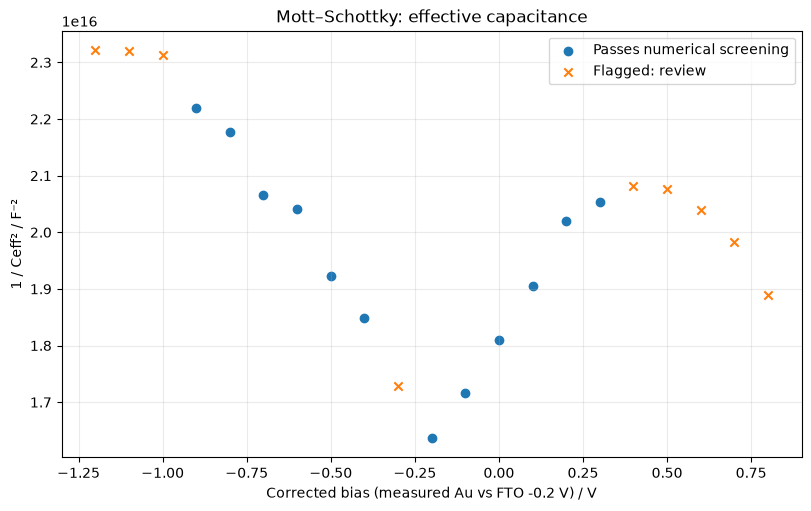

10 exploratory candidates; bounds are corrected bias in V. No range is selected automatically.


,n_points,voltage_min_v,voltage_max_v,span_v,slope,intercept,r_squared,rmse,flags
candidate,,,,,,,,,
0,4,-0.200373,0.100076,0.300449,8.994595e+15,1.812079e+16,0.998183,4.296863e+13,"(intercept_extrapolated,)"
1,4,-0.100404,0.200060,0.300465,1.004533e+16,1.812477e+16,0.997767,5.323137e+13,"(intercept_extrapolated,)"
2,5,-0.200373,0.200060,0.400433,9.538907e+15,1.817540e+16,0.995950,8.613832e+13,"(intercept_extrapolated,)"
3,6,-0.200373,0.300113,0.500486,8.810036e+15,1.812659e+16,0.988283,1.640306e+14,"(intercept_extrapolated,)"
4,5,-0.100404,0.300113,0.400517,8.823021e+15,1.812442e+16,0.979746,1.796646e+14,"(intercept_extrapolated,)"
5,6,-0.900334,-0.400380,0.499954,-7.533261e+15,1.556141e+16,0.979033,1.882577e+14,"(intercept_extrapolated,)"
6,5,-0.800343,-0.400380,0.399963,-7.962966e+15,1.533208e+16,0.973946,1.841626e+14,"(intercept_extrapolated,)"
7,5,-0.900334,-0.500369,0.399965,-7.283665e+15,1.575286e+16,0.963998,1.990524e+14,"(intercept_extrapolated,)"
8,4,-0.000352,0.300113,0.300465,8.404715e+15,1.820810e+16,0.960969,1.896397e+14,"(intercept_extrapolated,)"


In [8]:
BLOCKING_FLAGS = {
    "invalid_impedance_or_frequency", "invalid_voltage", "voltage_spread",
    "too_few_distinct_frequencies", "frequency_reversal", "incomplete_sweep",
    "missing_cycle", "possible_repeated_bias", "poor_relative_fit",
    "parameter_at_bound", "ill_conditioned", "fit_failed",
}
valid_results = fit_table.loc[
    fit_table["success"] & np.isfinite(fit_table["voltage_corrected_V"])
    & np.isfinite(fit_table["Ceff_F"]) & (fit_table["Ceff_F"] > 0)
].copy()
valid_results["eligible"] = valid_results["spectrum_id"].map(
    lambda sid: not bool(BLOCKING_FLAGS.intersection(fit_results[sid].flags))
)
valid_results["inverse_C2_F-2"] = inverse_capacitance_squared(valid_results["Ceff_F"].to_numpy())[0]
if valid_results.empty:
    print("No valid capacitances to plot.")
else:
    fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    for eligible, marker, label in [(True, "o", "Passes numerical screening"), (False, "x", "Flagged: review")]:
        part = valid_results.loc[valid_results["eligible"] == eligible]
        if not part.empty:
            ax.scatter(part["voltage_corrected_V"], part["inverse_C2_F-2"], marker=marker, label=label)
    ax.set(xlabel=f"Corrected bias (measured Au vs FTO {VOLTAGE_OFFSET_V:+g} V) / V",
           ylabel="1 / Ceff² / F⁻²", title="Mott–Schottky: effective capacitance")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()
    plt.close(fig)

eligible_ms = valid_results.loc[valid_results["eligible"]].sort_values("voltage_corrected_V").reset_index(drop=True)
windows = candidate_ranges(eligible_ms["voltage_corrected_V"].to_numpy(), eligible_ms["Ceff_F"].to_numpy(), min_span_v=0.3)
if fit_table["voltage_corrected_V"].isna().any():
    print("Warning: some spectra have no valid bias and cannot be placed in candidate windows.")
if not windows.empty:
    def contains_only_selected_spectra(window):
        in_range = fit_table.loc[fit_table["voltage_corrected_V"].between(window["voltage_min_v"], window["voltage_max_v"]), "spectrum_id"]
        chosen_ids = eligible_ms.iloc[list(window["indices"])]["spectrum_id"]
        return set(in_range) == set(chosen_ids)
    windows = windows.loc[windows.apply(contains_only_selected_spectra, axis=1)]
if windows.empty:
    print(f"No candidate ranges: {len(eligible_ms)} spectra pass screening.")
else:
    windows = windows.sort_values(["r_squared", "span_v"], ascending=[False, False], na_position="last").reset_index(drop=True)
    windows.index.name = "candidate"
    print(f"{len(windows)} exploratory candidates; bounds are corrected bias in V. No range is selected automatically.")
    display(windows.drop(columns="indices").head(10))

## Effective capacitance versus corrected voltage

The plot uses the same $V_{\mathrm{corrected}}=V_{\mathrm{meas}}-0.2\,\mathrm{V}$ convention as the Mott–Schottky plot. Capacitance is shown in nF. Error bars are one standard deviation from the local circuit-fit covariance where available; crosses denote fits flagged for review, for which uncertainty may be unavailable. $C_\mathrm{eff}$ is model-dependent and is not automatically a BiSI depletion capacitance.

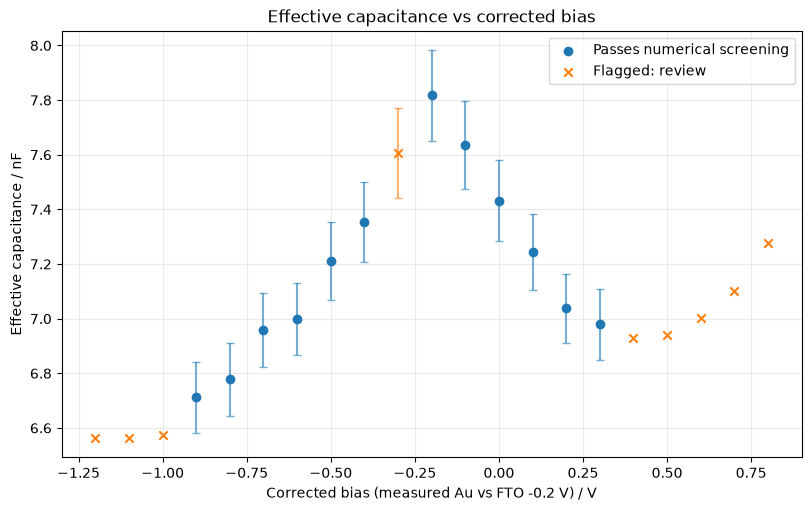

In [14]:
if valid_results.empty:
    print("No valid effective capacitances to plot.")
else:
    fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    for eligible, marker, color, label in (
        (True, "o", "tab:blue", "Passes numerical screening"),
        (False, "x", "tab:orange", "Flagged: review"),
    ):
        part = valid_results.loc[valid_results["eligible"] == eligible].sort_values("voltage_corrected_V")
        if part.empty:
            continue
        ax.scatter(part["voltage_corrected_V"], part["Ceff_F"] * 1e9,
                   marker=marker, color=color, label=label, zorder=3)
        has_uncertainty = np.isfinite(part["Ceff_std_F"]) & (part["Ceff_std_F"] >= 0)
        if has_uncertainty.any():
            ax.errorbar(part.loc[has_uncertainty, "voltage_corrected_V"],
                        part.loc[has_uncertainty, "Ceff_F"] * 1e9,
                        yerr=part.loc[has_uncertainty, "Ceff_std_F"] * 1e9,
                        fmt="none", ecolor=color, alpha=0.6, capsize=3, zorder=2)
    ax.set(xlabel=f"Corrected bias (measured Au vs FTO {VOLTAGE_OFFSET_V:+g} V) / V",
           ylabel="Effective capacitance / nF", title="Effective capacitance vs corrected bias")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()
    plt.close(fig)

In [4]:
# Verify the fixed shift changes only the voltage coordinates, not the slope.
if not windows.empty:
    idx = list(windows.iloc[0]["indices"])
    selected = eligible_ms.iloc[idx]
    y_test = selected["inverse_C2_F-2"].to_numpy(dtype=float)
    measured_fit = linear_regression(selected["voltage_measured_V"].to_numpy(dtype=float), y_test)
    corrected_fit = linear_regression(selected["voltage_corrected_V"].to_numpy(dtype=float), y_test)
    np.testing.assert_allclose(corrected_fit.slope, measured_fit.slope, rtol=1e-10)
    if measured_fit.x_intercept_v is not None and corrected_fit.x_intercept_v is not None:
        np.testing.assert_allclose(corrected_fit.x_intercept_v, measured_fit.x_intercept_v + VOLTAGE_OFFSET_V, atol=1e-10)
    print("Verified: the voltage shift preserves the slope and shifts the x-intercept by the configured offset.")
else:
    print("Offset verification awaits a candidate range.")

Verified: the voltage shift preserves the slope and shifts the x-intercept by the configured offset.


## Confirm the interval

After reviewing the original spectrum fits and candidate windows, set the candidate number and explicitly confirm the physical assumptions. The regression is unweighted. Its uncertainty omits area, dielectric constant, model selection, range selection, and uncertainty in the voltage offset. The corrected x-intercept is not automatically a flat-band voltage.

In [5]:
SELECTED_CANDIDATE = None  # e.g. 0, after reviewing the candidate table and fits
CONFIRM_MODEL_AND_RANGE = False
ms_regression = None
ms_density = None

if not CONFIRM_MODEL_AND_RANGE or SELECTED_CANDIDATE is None:
    print("No final estimate: explicitly select and confirm a candidate after reviewing the fits.")
elif SELECTED_CANDIDATE not in windows.index:
    print("Selected candidate does not exist.")
else:
    chosen = windows.loc[SELECTED_CANDIDATE]
    selected_data = eligible_ms.iloc[list(chosen["indices"])].copy()
    v = selected_data["voltage_corrected_V"].to_numpy(dtype=float)
    y = selected_data["inverse_C2_F-2"].to_numpy(dtype=float)
    ms_regression = linear_regression(v, y)
    if ms_regression.x_intercept_v is None:
        print("Slope is too small or the intercept is unavailable; density not calculated.")
    else:
        ms_density = carrier_density(ms_regression, area_m2=AREA_CM2 * 1e-4,
                                     relative_permittivity=RELATIVE_PERMITTIVITY,
                                     confirmed=CONFIRM_MODEL_AND_RANGE)
        print(f"Selected spectra: {selected_data['spectrum_id'].tolist()}")
        print(f"Slope: {ms_regression.slope:.5e} ± {np.sqrt(ms_regression.covariance[0, 0]):.2e} F⁻² V⁻¹")
        print(f"Corrected x-intercept: {ms_regression.x_intercept_v:.5g} ± {ms_regression.x_intercept_std_v:.2g} V")
        print(f"Measured-bias x-intercept: {ms_regression.x_intercept_v - VOLTAGE_OFFSET_V:.5g} V")
        print(f"Conditional effective carrier concentration: {ms_density['density_cm3']:.4e} ± {ms_density['std_cm3']:.2e} cm⁻³")
        print(f"Corrected fit range: {v.min():.4f} to {v.max():.4f} V; R²={ms_regression.r_squared:.4f}; flags: {', '.join(ms_regression.flags) or 'none'}")
        print("Offset uncertainty is not included; x-intercept is not automatically a flat-band voltage.")
        fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
        ax.scatter(valid_results["voltage_corrected_V"], valid_results["inverse_C2_F-2"], alpha=0.45, label="All valid capacitances")
        ax.scatter(v, y, label="Selected for regression")
        line_v = np.linspace(v.min(), v.max(), 200)
        ax.plot(line_v, ms_regression.slope * line_v + ms_regression.intercept, label="Unweighted linear fit")
        ax.set(xlabel=f"Corrected bias (measured Au vs FTO {VOLTAGE_OFFSET_V:+g} V) / V",
               ylabel="1 / Ceff² / F⁻²", title="Selected Mott–Schottky range")
        ax.grid(alpha=0.25)
        ax.legend()
        plt.show()
        plt.close(fig)

No final estimate: explicitly select and confirm a candidate after reviewing the fits.


## Trial fit: corrected bias −0.25 to +0.30 V

This exploratory calculation uses the requested interval with **strict inclusive bounds** and only spectra that pass the existing screening. The measured point at approximately +0.3001 V corrected is just outside +0.30 V and is therefore excluded. The displayed uncertainty describes the unweighted line fit only; it does not include uncertainty in capacitances, area, permittivity, voltage offset, model or chosen range. The carrier concentration is conditional on the fitted effective capacitance representing BiSI depletion capacitance; no physical attribution or flat-band interpretation is established.

Requested corrected interval: [-1.000, -0.100] V; 8 eligible spectra, 1 screened out.
Strict bounds: the point near +0.3001 V is outside the upper limit.


,spectrum_id,voltage_measured_V,voltage_corrected_V,Ceff_F,inverse_C2_F-2,relative_RMSE,flags
3,4,-0.700334,-0.900334,6.711460e-09,2.220067e+16,0.086417,user_excluded_points
4,5,-0.600343,-0.800343,6.777756e-09,2.176848e+16,0.089716,user_excluded_points
5,6,-0.500300,-0.700300,6.958968e-09,2.064954e+16,0.089766,user_excluded_points
6,7,-0.400324,-0.600324,6.998890e-09,2.041463e+16,0.086626,user_excluded_points
7,8,-0.300369,-0.500369,7.210133e-09,1.923594e+16,0.092476,user_excluded_points
8,9,-0.200380,-0.400380,7.353264e-09,1.849438e+16,0.093341,user_excluded_points
10,11,-0.000373,-0.200373,7.816883e-09,1.636563e+16,0.098816,user_excluded_points
11,12,0.099596,-0.100404,7.634970e-09,1.715479e+16,0.096933,user_excluded_points


Spectra inside the interval that did not pass screening:


,spectrum_id,voltage_corrected_V,flags
9,10,-0.300321,"user_excluded_points, poor_relative_fit"


Slope: -7.30530e+15 ± 6.44e+14 F⁻² V⁻¹ (unweighted OLS, 1σ)
R² = 0.95549; RMSE = 4.153e+14 F⁻²; flags: intercept_extrapolated
Corrected x-intercept: 2.1488 ± 0.2368 V (1σ)
Measured-bias x-intercept: 2.3488 V
Conditional effective carrier concentration: 6.270e+16 ± 5.52e+15 cm⁻³ (slope uncertainty only)
The x-intercept is extrapolated outside the fit range and is not automatically a flat-band voltage.
The concentration is a trial estimate conditional on the depletion-capacitance model.


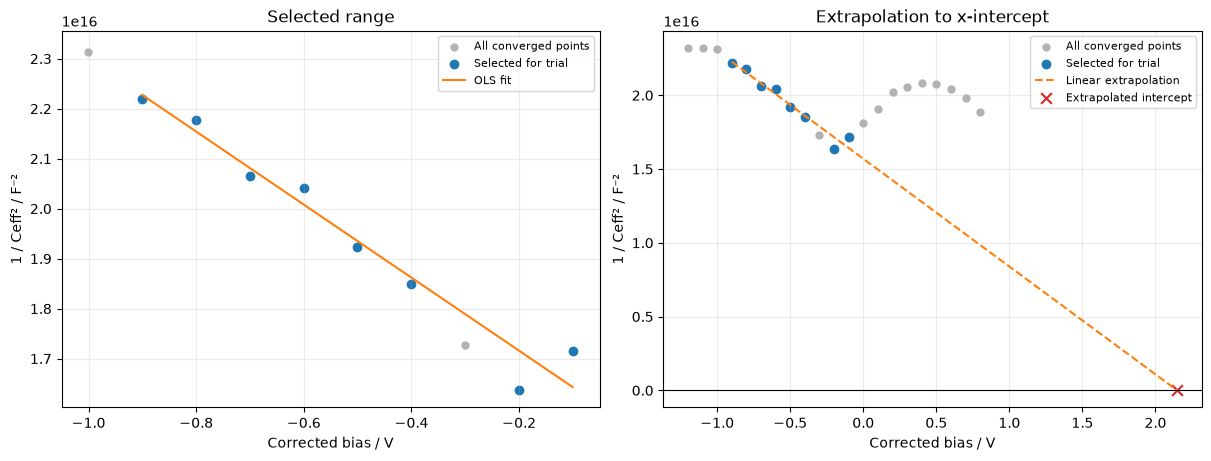

In [13]:
from scipy.constants import elementary_charge, epsilon_0

TRIAL_V_MIN = -1 # corrected bias / V, inclusive
TRIAL_V_MAX = -0.10  # corrected bias / V, inclusive
trial_data = valid_results.loc[
    valid_results["eligible"]
    & valid_results["voltage_corrected_V"].between(TRIAL_V_MIN, TRIAL_V_MAX)
].sort_values("voltage_corrected_V").copy()
excluded_in_range = fit_table.loc[
    fit_table["voltage_corrected_V"].between(TRIAL_V_MIN, TRIAL_V_MAX)
    & ~fit_table["spectrum_id"].isin(trial_data["spectrum_id"])
]
print(f"Requested corrected interval: [{TRIAL_V_MIN:.3f}, {TRIAL_V_MAX:.3f}] V; "
      f"{len(trial_data)} eligible spectra, {len(excluded_in_range)} screened out.")
print("Strict bounds: the point near +0.3001 V is outside the upper limit.")
display(trial_data[["spectrum_id", "voltage_measured_V", "voltage_corrected_V", "Ceff_F", "inverse_C2_F-2", "relative_RMSE", "flags"]])
if not excluded_in_range.empty:
    print("Spectra inside the interval that did not pass screening:")
    display(excluded_in_range[["spectrum_id", "voltage_corrected_V", "flags"]])

trial_fit = None
trial_density_cm3 = None
if len(trial_data) < 4 or trial_data["voltage_corrected_V"].nunique() < 4:
    print("At least four distinct eligible voltages are required for the trial regression.")
else:
    x_trial = trial_data["voltage_corrected_V"].to_numpy(dtype=float)
    y_trial = trial_data["inverse_C2_F-2"].to_numpy(dtype=float)
    trial_fit = linear_regression(x_trial, y_trial)
    slope_std = float(np.sqrt(trial_fit.covariance[0, 0]))
    print(f"Slope: {trial_fit.slope:.5e} ± {slope_std:.2e} F⁻² V⁻¹ (unweighted OLS, 1σ)")
    print(f"R² = {trial_fit.r_squared:.5f}; RMSE = {trial_fit.rmse:.3e} F⁻²; flags: {', '.join(trial_fit.flags) or 'none'}")
    if trial_fit.x_intercept_v is None:
        print("Slope is too small to calculate a reliable intercept or carrier estimate.")
    elif AREA_CM2 <= 0 or RELATIVE_PERMITTIVITY <= 0:
        print("A positive electrode area and relative permittivity are required for the carrier estimate.")
    else:
        trial_density_cm3 = 2 / (elementary_charge * epsilon_0 * RELATIVE_PERMITTIVITY
                                 * (AREA_CM2 * 1e-4)**2 * abs(trial_fit.slope)) * 1e-6
        trial_density_std_cm3 = trial_density_cm3 * slope_std / abs(trial_fit.slope)
        print(f"Corrected x-intercept: {trial_fit.x_intercept_v:.4f} ± {trial_fit.x_intercept_std_v:.4f} V (1σ)")
        print(f"Measured-bias x-intercept: {trial_fit.x_intercept_v - VOLTAGE_OFFSET_V:.4f} V")
        print(f"Conditional effective carrier concentration: {trial_density_cm3:.3e} ± {trial_density_std_cm3:.2e} cm⁻³ (slope uncertainty only)")
        print("The x-intercept is extrapolated outside the fit range and is not automatically a flat-band voltage.")
        print("The concentration is a trial estimate conditional on the depletion-capacitance model.")

        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
        for ax in axes:
            ax.scatter(valid_results["voltage_corrected_V"], valid_results["inverse_C2_F-2"],
                       color="0.7", s=25, label="All converged points")
            ax.scatter(x_trial, y_trial, color="tab:blue", label="Selected for trial")
            ax.grid(alpha=0.25)
            ax.set_xlabel("Corrected bias / V")
            ax.set_ylabel("1 / Ceff² / F⁻²")
        line_fit = np.linspace(x_trial.min(), x_trial.max(), 200)
        axes[0].plot(line_fit, trial_fit.slope * line_fit + trial_fit.intercept, color="tab:orange", label="OLS fit")
        axes[0].set_xlim(TRIAL_V_MIN - 0.05, TRIAL_V_MAX + 0.05)
        axes[0].set_title("Selected range")
        line_ext = np.linspace(min(x_trial.min(), trial_fit.x_intercept_v), max(x_trial.max(), trial_fit.x_intercept_v), 300)
        axes[1].plot(line_ext, trial_fit.slope * line_ext + trial_fit.intercept, "--", color="tab:orange", label="Linear extrapolation")
        axes[1].axhline(0, color="black", linewidth=0.8)
        axes[1].scatter([trial_fit.x_intercept_v], [0], color="tab:red", marker="x", s=60, label="Extrapolated intercept")
        axes[1].set_title("Extrapolation to x-intercept")
        for ax in axes:
            ax.legend(fontsize=8)
        plt.show()
        plt.close(fig)